<a href="https://colab.research.google.com/github/Prakritipi/ML-Final-Project/blob/main/MLFinalProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Install and Imports

In [ ]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost", "shap"], check=False)

import os, time, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from scipy.stats import kendalltau, theilslopes
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss,
                             silhouette_score)
import xgboost as xgb

warnings.filterwarnings("ignore")
RNG = 42
np.random.seed(RNG)
OUT = "/content/glacier_data"
os.makedirs(OUT, exist_ok=True)

### 2. Configuration

In [ ]:
# Set True ONLY to test the pipeline on synthetic numbers. Never use for results.
DEMO_MODE = False

START = "19810101"
END = (pd.Timestamp.today() - pd.Timedelta(days=10)).strftime("%Y%m%d")

SITES = {
    "Manaslu":      dict(lat=28.55, lon=84.64, z_glacier=5000),  # Samagaun / Birendra Tal
    "Khumbu":       dict(lat=27.99, lon=86.85, z_glacier=5300),  # Everest / Khumbu glacier
    "Langtang":     dict(lat=28.20, lon=85.55, z_glacier=5000),
    "Dhaulagiri":   dict(lat=28.70, lon=83.40, z_glacier=5200),
    "Kanchenjunga": dict(lat=27.70, lon=88.15, z_glacier=5200),
    "Saipal":       dict(lat=29.85, lon=80.95, z_glacier=5000),
}
PARAMS = ["T2M", "T2M_MAX", "T2M_MIN", "T2MDEW", "RH2M", "PRECTOTCORR",
          "WS2M", "PS", "ALLSKY_SFC_SW_DWN", "ALLSKY_SFC_LW_DWN"]

LAPSE = 0.0065        # K per m, standard environmental lapse rate (assumption)
DDF = 5.0             # mm w.e. per degC per day, degree-day factor (assumption)
LABEL_Q = 0.66        # a day is "melt-favorable" if next-day melt exceeds this
                      # quantile of the site's TRAINING-period melt (floored at 0)
TRAIN_END, VAL_END = 2014, 2019   # chronological split: train / val / test

### 3. Download NASA POWER Daily Data (or Demo Data)

In [ ]:
def fetch_power(name, lat, lon):
    url = "https://power.larc.nasa.gov/api/temporal/daily/point"
    q = dict(parameters=",".join(PARAMS), community="RE", longitude=lon,
             latitude=lat, start=START, end=END, format="JSON")
    last = None
    for attempt in range(4):
        try:
            r = requests.get(url, params=q, timeout=240)
            r.raise_for_status()
            js = r.json()
            break
        except Exception as e:  # retry on network / server errors
            last = e
            print(f"  {name}: attempt {attempt+1} failed ({e}); retrying")
            time.sleep(5 * (attempt + 1))
    else:
        raise RuntimeError(f"Could not download {name}: {last}")
    df = pd.DataFrame(js["properties"]["parameter"])
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    df = df.replace(-999, np.nan).sort_index()
    df["z_cell"] = float(js["geometry"]["coordinates"][2])
    return df

def synthetic(name, meta, seed):
    rng = np.random.default_rng(seed)
    idx = pd.date_range(START, END, freq="D")
    doy = idx.dayofyear.values
    base = -8 + 9 * np.sin(2 * np.pi * (doy - 110) / 365.25)
    trend = np.linspace(0, 1.2, len(idx))
    t = base + trend + rng.normal(0, 2.5, len(idx))
    df = pd.DataFrame(index=idx)
    df["T2M"] = t
    df["T2M_MAX"] = t + 4 + rng.normal(0, 1, len(idx))
    df["T2M_MIN"] = t - 4 + rng.normal(0, 1, len(idx))
    df["T2MDEW"] = t - 6 + rng.normal(0, 2, len(idx))
    df["RH2M"] = np.clip(60 + 25 * np.sin(2 * np.pi * (doy - 170) / 365.25) + rng.normal(0, 10, len(idx)), 5, 100)
    df["PRECTOTCORR"] = np.clip(rng.gamma(0.4, 6, len(idx)) * (doy > 150) * (doy < 270), 0, None)
    df["WS2M"] = np.abs(rng.normal(3, 1.2, len(idx)))
    df["PS"] = 60 + rng.normal(0, 0.5, len(idx))
    df["ALLSKY_SFC_SW_DWN"] = np.clip(15 + 8 * np.sin(2 * np.pi * (doy - 80) / 365.25) + rng.normal(0, 3, len(idx)), 1, None)
    df["ALLSKY_SFC_LW_DWN"] = 200 + 0.8 * t + rng.normal(0, 8, len(idx))
    df["z_cell"] = 3800.0 + 300 * seed
    return df

RAW = {}
for i, (name, meta) in enumerate(SITES.items()):
    path = f"{OUT}/power_{name}.csv"
    if DEMO_MODE:
        print("!!! DEMO_MODE: synthetic data, NOT real observations !!!") if i == 0 else None
        RAW[name] = synthetic(name, meta, i)
    elif os.path.exists(path):
        RAW[name] = pd.read_csv(path, index_col=0, parse_dates=True)
        print(f"{name}: loaded cache ({len(RAW[name]):,} days)")
    else:
        print(f"{name}: downloading ...")
        RAW[name] = fetch_power(name, meta["lat"], meta["lon"])
        RAW[name].to_csv(path)

# Sanity check
names = list(RAW)
for a in range(len(names)):
    for b in range(a + 1, len(names)):
        if RAW[names[a]]["T2M"].equals(RAW[names[b]]["T2M"]):
            print(f"WARNING: {names[a]} and {names[b]} share a grid cell; move one site.")
print("Raw rows (before feature lags):", sum(len(v) for v in RAW.values()))

Manaslu: downloading ...
Khumbu: downloading ...
Langtang: downloading ...
Dhaulagiri: downloading ...
Kanchenjunga: downloading ...
Saipal: downloading ...
Raw rows (before feature lags): 100386


### 4. Feature Engineering (Physics-aware, no look-ahead)

In [ ]:
def site_features(df, site, meta, dT=0.0):
    d = df.copy()
    zc, zg = d["z_cell"].iloc[0], meta["z_glacier"]
    adj = -LAPSE * (zg - zc)                       # cell -> glacier elevation
    d["Tg"] = d["T2M"] + dT + adj
    d["Tg_max"] = d["T2M_MAX"] + dT + adj
    d["Tg_min"] = d["T2M_MIN"] + dT + adj
    d["PDD"] = d["Tg"].clip(lower=0)
    d["melt_mm"] = DDF * d["PDD"]                  # degree-day melt proxy
    d["dTg"] = d["Tg"].diff()
    d["DTR"] = d["Tg_max"] - d["Tg_min"]
    for w in (3, 7, 14, 30):
        d[f"Tg_m{w}"] = d["Tg"].rolling(w).mean()
        d[f"P_s{w}"] = d["PRECTOTCORR"].rolling(w).sum()
    for w in (7, 30):
        d[f"SW_m{w}"] = d["ALLSKY_SFC_SW_DWN"].rolling(w).mean()
    for l in (1, 2, 3):
        d[f"Tg_l{l}"] = d["Tg"].shift(l)
    d["PDD_cum30"] = d["PDD"].rolling(30).sum()
    d["frac_pos7"] = (d["Tg"] > 0).rolling(7).mean()
    doy = d.index.dayofyear.values
    d["doy"] = doy
    d["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    d["site"] = site
    d["lat"], d["lon"] = meta["lat"], meta["lon"]
    d["z_glacier"], d["z_cell_m"] = zg, zc
    d["melt_next"] = d["melt_mm"].shift(-1)        # target source (t+1)
    d["year"] = d.index.year
    return d

def build_all(dT=0.0):
    parts = [site_features(RAW[n], n, m, dT) for n, m in SITES.items()]
    return pd.concat(parts)

full = build_all(0.0)
full = full.dropna().copy()
print(f"Modelling rows after lags / next-day target: {len(full):,}")

train_mask = full["year"] <= TRAIN_END
CLIM = (full[train_mask].groupby(["site", "doy"])["Tg"].mean()
        .groupby(level=0).transform(lambda s: s.rolling(15, center=True, min_periods=1).mean())
        .rename("Tg_clim").reset_index())
THR = (full[train_mask].groupby("site")["melt_mm"]
       .quantile(LABEL_Q).clip(lower=0).to_dict())
print("Label thresholds (mm w.e./day) per site:", {k: round(v, 2) for k, v in THR.items()})

def finalize(d):
    d = d.merge(CLIM, on=["site", "doy"], how="left").set_index(d.index)
    d["Tg_anom"] = d["Tg"] - d["Tg_clim"]
    thr = d["site"].map(THR)
    d["y"] = (d["melt_next"] > thr).astype(int)           # target: melt-favorable tomorrow
    d["persist"] = (d["melt_mm"] > thr).astype(int)       # baseline: today's state
    return d

full = finalize(full)
EXCL = {"melt_next", "y", "persist", "site", "year", "Tg_clim"}
FEATS = [c for c in full.columns if c not in EXCL and pd.api.types.is_numeric_dtype(full[c])]
REGIME = ["Tg", "Tg_m7", "SW_m7", "RH2M", "P_s7", "WS2M", "Tg_anom", "PDD_cum30"]

tr = full[full["year"] <= TRAIN_END]
va = full[(full["year"] > TRAIN_END) & (full["year"] <= VAL_END)]
te = full[full["year"] > VAL_END]
print(f"train {len(tr):,} | val {len(va):,} | test {len(te):,} | positive rate train {tr['y'].mean():.2f}")
full.to_csv(f"{OUT}/modelling_dataset.csv")

Modelling rows after lags / next-day target: 85,014
Label thresholds (mm w.e./day) per site: {'Dhaulagiri': 0.0, 'Kanchenjunga': 0.0, 'Khumbu': 0.0, 'Langtang': 0.0, 'Manaslu': 0.0, 'Saipal': 0.0}
train 59,142 | val 10,956 | test 14,916 | positive rate train 0.26


### 5. Exploratory Analysis and Long-Term Trends

        site  kendall_tau  p_value  sen_slope_PDD_per_yr  temp_trend_C_per_decade
  Dhaulagiri       -0.235   0.0380                 -0.79                   -0.035
Kanchenjunga        0.266   0.0187                  0.68                    0.169
      Khumbu        0.266   0.0187                  1.13                    0.167
    Langtang       -0.129   0.2526                 -0.63                    0.014
     Manaslu       -0.101   0.3721                 -0.49                    0.008
      Saipal        0.058   0.6062                  0.34                    0.049


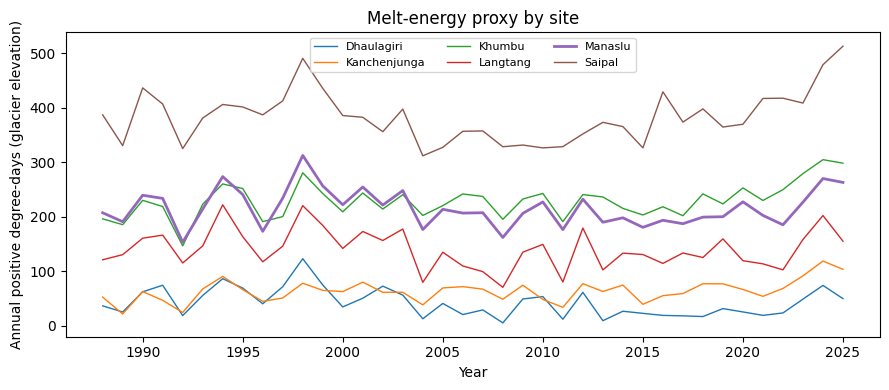

In [ ]:
last_full = full["year"].max() - 1
ann = (full[full["year"] <= last_full]
       .groupby(["site", "year"]).agg(melt_days=("PDD", lambda s: (s > 0).sum()),
                                      PDD_sum=("PDD", "sum"),
                                      Tg_mean=("Tg", "mean")).reset_index())
rows = []
for s, g in ann.groupby("site"):
    tau, p = kendalltau(g["year"], g["PDD_sum"])
    slope, icpt, lo, hi = theilslopes(g["PDD_sum"], g["year"])
    rows.append(dict(site=s, kendall_tau=round(tau, 3), p_value=round(p, 4),
                     sen_slope_PDD_per_yr=round(slope, 2),
                     temp_trend_C_per_decade=round(10 * theilslopes(g["Tg_mean"], g["year"])[0], 3)))
trend_tbl = pd.DataFrame(rows)
print(trend_tbl.to_string(index=False))
trend_tbl.to_csv(f"{OUT}/trend_table.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
for s, g in ann.groupby("site"):
    ax.plot(g["year"], g["PDD_sum"], label=s, lw=2 if s == "Manaslu" else 1)
ax.set_xlabel("Year"); ax.set_ylabel("Annual positive degree-days (glacier elevation)")
ax.set_title("Melt-energy proxy by site"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_pdd_trend.png", dpi=200); plt.show()

### 6. Hybrid Model: K-Means Regimes -> XGBoost

In [ ]:
sc = StandardScaler().fit(tr[REGIME])
Xr_tr = sc.transform(tr[REGIME])

sub = np.random.default_rng(RNG).choice(len(Xr_tr), size=min(12000, len(Xr_tr)), replace=False)
scores = {}
for k in range(3, 9):
    km_ = KMeans(n_clusters=k, n_init=5, random_state=RNG).fit(Xr_tr[sub])
    scores[k] = silhouette_score(Xr_tr[sub], km_.labels_)
K = max(scores, key=scores.get)
print("Silhouette by k:", {k: round(v, 3) for k, v in scores.items()}, "-> K =", K)
km = KMeans(n_clusters=K, n_init=10, random_state=RNG).fit(Xr_tr)

def add_regimes(d):
    Xr = sc.transform(d[REGIME])
    dist = km.transform(Xr)
    out = d[FEATS].copy()
    out["regime"] = km.predict(Xr)
    for j in range(K):
        out[f"dist_c{j}"] = dist[:, j]
    return out

H_tr, H_va, H_te = add_regimes(tr), add_regimes(va), add_regimes(te)
B_tr, B_va, B_te = tr[FEATS], va[FEATS], te[FEATS]

def make_xgb():
    return xgb.XGBClassifier(n_estimators=1500, learning_rate=0.05, max_depth=6,
                             subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                             reg_lambda=2.0, tree_method="hist", eval_metric="logloss",
                             early_stopping_rounds=50, random_state=RNG, n_jobs=-1)

m_base = make_xgb().fit(B_tr, tr["y"], eval_set=[(B_va, va["y"])], verbose=False)
m_hyb = make_xgb().fit(H_tr, tr["y"], eval_set=[(H_va, va["y"])], verbose=False)
lr = LogisticRegression(max_iter=2000).fit(StandardScaler().fit(B_tr).transform(B_tr), tr["y"])
lr_sc = StandardScaler().fit(B_tr)

def metrics(y, p, hard=None):
    hard = (p >= 0.5).astype(int) if hard is None else hard
    return dict(Accuracy=accuracy_score(y, hard), F1=f1_score(y, hard),
                ROC_AUC=roc_auc_score(y, p), PR_AUC=average_precision_score(y, p),
                Brier=brier_score_loss(y, np.clip(p, 0, 1)))

res = {
    "Persistence (today's state)": metrics(te["y"], te["persist"].values, te["persist"].values),
    "Logistic regression": metrics(te["y"], lr.predict_proba(lr_sc.transform(B_te))[:, 1]),
    "XGBoost only": metrics(te["y"], m_base.predict_proba(B_te)[:, 1]),
    "K-means + XGBoost (hybrid)": metrics(te["y"], m_hyb.predict_proba(H_te)[:, 1]),
}
res_tbl = pd.DataFrame(res).T.round(4)
print("\nTEST SET (chronological hold-out, years >", VAL_END, ")")
print(res_tbl.to_string())
res_tbl.to_csv(f"{OUT}/model_comparison.csv")

per_site = []
for s, g in te.groupby("site"):
    p = m_hyb.predict_proba(add_regimes(g))[:, 1]
    per_site.append(dict(site=s, **{k: round(v, 3) for k, v in metrics(g["y"], p).items()}))
print(pd.DataFrame(per_site).to_string(index=False))

Silhouette by k: {3: np.float64(0.246), 4: np.float64(0.222), 5: np.float64(0.228), 6: np.float64(0.232), 7: np.float64(0.241), 8: np.float64(0.218)} -> K = 3

TEST SET (chronological hold-out, years > 2019 )
                             Accuracy      F1  ROC_AUC  PR_AUC   Brier
Persistence (today's state)    0.9575  0.9242   0.9473  0.8755  0.0425
Logistic regression            0.9609  0.9297   0.9940  0.9846  0.0281
XGBoost only                   0.9619  0.9315   0.9942  0.9852  0.0276
K-means + XGBoost (hybrid)     0.9610  0.9299   0.9941  0.9851  0.0278
        site  Accuracy    F1  ROC_AUC  PR_AUC  Brier
  Dhaulagiri     0.917 0.698    0.971   0.843  0.052
Kanchenjunga     0.956 0.910    0.989   0.960  0.035
      Khumbu     0.971 0.955    0.997   0.993  0.022
    Langtang     0.967 0.947    0.996   0.991  0.023
     Manaslu     0.973 0.958    0.997   0.994  0.020
      Saipal     0.981 0.972    0.998   0.997  0.015


### 7. Spatial Generalisation: Leave-One-Site-Out

In [ ]:
loso = []
for s in SITES:
    a, b = full[full["site"] != s], full[(full["site"] == s) & (full["year"] > VAL_END)]
    a = a[a["year"] <= VAL_END]
    m = xgb.XGBClassifier(n_estimators=300, learning_rate=0.08, max_depth=6, subsample=0.8,
                          colsample_bytree=0.8, tree_method="hist", random_state=RNG, n_jobs=-1)
    m.fit(a[FEATS], a["y"])
    p = m.predict_proba(b[FEATS])[:, 1]
    loso.append(dict(held_out_site=s, **{k: round(v, 3) for k, v in metrics(b["y"], p).items()}))
loso_tbl = pd.DataFrame(loso)
print(loso_tbl.to_string(index=False))
loso_tbl.to_csv(f"{OUT}/loso_results.csv", index=False)

held_out_site  Accuracy    F1  ROC_AUC  PR_AUC  Brier
      Manaslu     0.971 0.954    0.997   0.994  0.021
       Khumbu     0.968 0.949    0.997   0.993  0.023
     Langtang     0.962 0.937    0.995   0.989  0.025
   Dhaulagiri     0.924 0.769    0.970   0.836  0.054
 Kanchenjunga     0.955 0.909    0.988   0.959  0.035
       Saipal     0.978 0.968    0.998   0.997  0.015


### 8. Explainability (SHAP) and Regime Interpretation

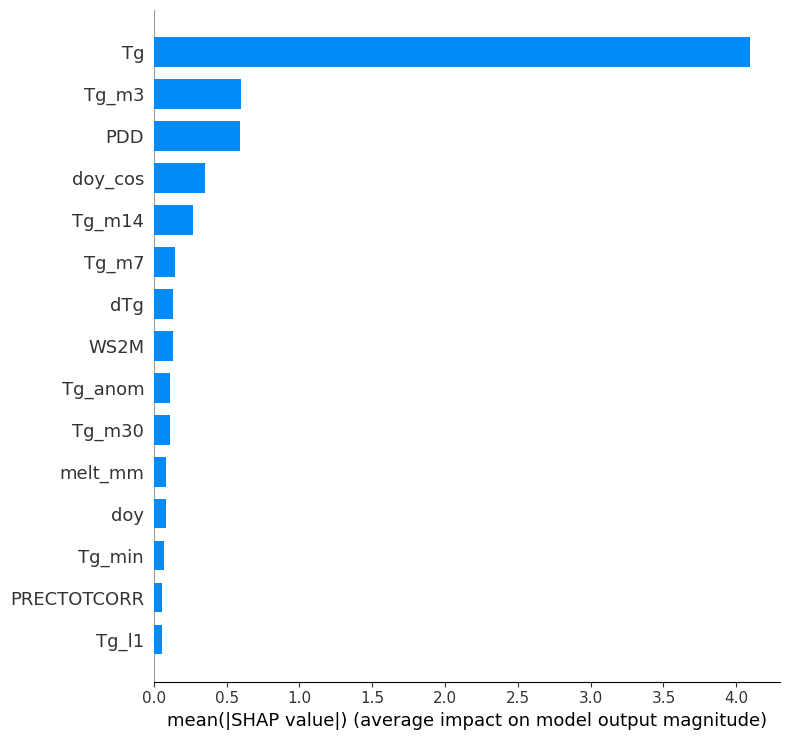


Weather regimes found by K-means (training years):
           Tg  SW_m7   RH2M   P_s7  PDD_cum30     y  share_%
regime                                                      
0       -3.30   5.82  59.50   4.56       3.84  0.17     29.9
1        1.01   4.66  84.88  34.05      45.05  0.70     29.6
2      -11.20   4.00  52.38   2.31       0.05  0.00     40.5


In [ ]:
try:
    import shap
    samp = H_te.sample(min(3000, len(H_te)), random_state=RNG)
    sv = shap.TreeExplainer(m_hyb).shap_values(samp)
    shap.summary_plot(sv, samp, plot_type="bar", max_display=15, show=False)
    plt.tight_layout(); plt.savefig(f"{OUT}/fig_shap.png", dpi=200); plt.show()
except Exception as e:
    print("SHAP skipped:", e)

prof = tr.assign(regime=km.predict(sc.transform(tr[REGIME]))).groupby("regime")[
    ["Tg", "SW_m7", "RH2M", "P_s7", "PDD_cum30", "y"]].mean().round(2)
prof["share_%"] = (tr.assign(regime=km.predict(sc.transform(tr[REGIME]))).groupby("regime").size() / len(tr) * 100).round(1)
print("\nWeather regimes found by K-means (training years):")
print(prof.to_string())
prof.to_csv(f"{OUT}/regime_profile.csv")

### 9. "Future Occurrence": Warming-Scenario Sensitivity

In [ ]:
def scenario(dT):
    d = build_all(dT).dropna()
    d = finalize(d)
    d = d[d["year"] > VAL_END]
    d = d[d["year"] <= d["year"].max() - 1] if d["year"].nunique() > 1 else d
    p = m_hyb.predict_proba(add_regimes(d))[:, 1]
    d = d.assign(p=p, hit=(p >= 0.5).astype(int))
    return d.groupby(["site", "year"])["hit"].sum().groupby("site").mean()

sc_tbl = pd.DataFrame({f"+{dT} C": scenario(dT) for dT in (0.0, 1.5, 2.0, 3.0)}).round(1)
sc_tbl["extra_days_at_+2C"] = (sc_tbl["+2.0 C"] - sc_tbl["+0.0 C"]).round(1)
print("Mean predicted melt-favorable days per year (test years):")
print(sc_tbl.to_string())
sc_tbl.to_csv(f"{OUT}/scenario_table.csv")

Mean predicted melt-favorable days per year (test years):
              +0.0 C  +1.5 C  +2.0 C  +3.0 C  extra_days_at_+2C
site                                                           
Dhaulagiri      43.7   107.3   117.8   139.2               74.1
Kanchenjunga    87.8   123.2   132.0   145.3               44.2
Khumbu         115.7   134.2   141.3   153.8               25.6
Langtang       109.3   143.0   152.3   166.7               43.0
Manaslu        115.0   138.2   146.2   164.0               31.2
Saipal         121.2   137.3   143.7   158.2               22.5


### 10. Hazard-Stress Precursors

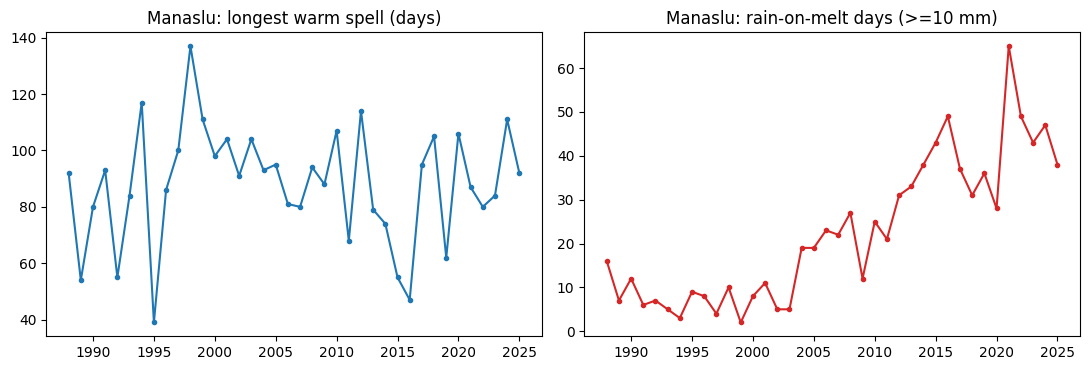

In [ ]:
def longest_run(b):
    best = cur = 0
    for v in b:
        cur = cur + 1 if v else 0
        best = max(best, cur)
    return best

rows = []
for (s, y), g in full[full["year"] <= last_full].groupby(["site", "year"]):
    warm = (g["Tg"] > 0).values
    rows.append(dict(site=s, year=y,
                     longest_warm_spell_days=longest_run(warm),
                     rain_on_melt_days=int(((g["PRECTOTCORR"] >= 10) & (g["Tg"] > 0)).sum()),
                     extreme_melt_days=int((g["melt_mm"] > g["melt_mm"].quantile(0.95)).sum())))
haz = pd.DataFrame(rows)
mn = haz[haz["site"] == "Manaslu"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(mn["year"], mn["longest_warm_spell_days"], marker="o", ms=3)
ax[0].set_title("Manaslu: longest warm spell (days)")
ax[1].plot(mn["year"], mn["rain_on_melt_days"], marker="o", ms=3, color="tab:red")
ax[1].set_title("Manaslu: rain-on-melt days (>=10 mm)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_hazard_stress.png", dpi=200); plt.show()
haz.to_csv(f"{OUT}/hazard_stress_index.csv", index=False)

### 11. Save Model Artefacts

In [ ]:
import joblib
joblib.dump(dict(model=m_hyb, scaler=sc, kmeans=km, feats=FEATS, regime=REGIME,
                 thresholds=THR), f"{OUT}/hybrid_kmeans_xgb.joblib")
print("Saved to", OUT)

Saved to /content/glacier_data


### 12. Deep Dive: Manaslu / Birendra Tal Specialized Risk Warning & Disaster Prevention Analysis

To aid in GLOF and glacial lake outburst monitoring (e.g., Birendra Tal), we design a localized, physics-informed **Run-off Hazard Index (RHI)**. This incorporates:
- **Melt runoff proxy:** Cumulative positive degree days calculated using high-resolution lapse-rate modified temperatures.
- **Rain-on-Melt (RoM) Synergies:** Liquid rainfall entering a melting glacier snowpack dramatically accelerates structural failure.
- **Thermal Refreeze Deficit:** Tracking nights where $T_{min} > 0^\circ\text{C}$ indicating zero nighttime thermal recovery (critical for structural instability).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, precision_recall_curve

# 1. Extract and focus deeply on Manaslu
manaslu_df = full[full['site'] == 'Manaslu'].copy()

# 2. Construct the specialized Run-off Hazard Index (RHI)
# RHI = melt_mm + (Precipitation if Tg > 0 else 0) + NightRefreezeDeficit
manaslu_df['nighttime_deficit'] = manaslu_df['Tg_min'].clip(lower=0) * 2.0
manaslu_df['rain_on_melt_active'] = np.where(manaslu_df['Tg'] > 0, manaslu_df['PRECTOTCORR'], 0.0)
manaslu_df['RHI'] = manaslu_df['melt_mm'] + manaslu_df['rain_on_melt_active'] + manaslu_df['nighttime_deficit']

# Calculate a rolling 3-day accumulated runoff stress index (critical for lake level surges)
manaslu_df['RHI_accum3d'] = manaslu_df['RHI'].rolling(3).sum()

# 3. Label high-hazard risk anomalies (top 5% of historical baseline training values)
train_ref = manaslu_df[manaslu_df['year'] <= TRAIN_END]
hazard_threshold = train_ref['RHI_accum3d'].quantile(0.95)
manaslu_df['GLOF_risk_trigger'] = (manaslu_df['RHI_accum3d'] > hazard_threshold).astype(int)

print(f"Manaslu 95th Percentile 3-day Run-off Hazard Threshold: {hazard_threshold:.2f} mm equivalent water output/day")
print(f"Total predicted GLOF risk trigger events in chronological test dataset (>2019): {manaslu_df.loc[manaslu_df['year'] > VAL_END, 'GLOF_risk_trigger'].sum()} times")

Manaslu 95th Percentile 3-day Run-off Hazard Threshold: 60.11 mm equivalent water output/day
Total predicted GLOF risk trigger events in chronological test dataset (>2019): 386 times


### 13. Training a Dedicated Localized Manaslu Disaster Warning Classifier

We train a predictive warning model specifically using the Manaslu climate dataset, utilizing next-day risk targets to preemptively trigger downstream warning alerts.

In [ ]:
# Shift target to predict extreme runoff risk 24-48 hours in advance
manaslu_df['target_hazard_tomorrow'] = manaslu_df['GLOF_risk_trigger'].shift(-1)
manaslu_df_final = manaslu_df.dropna()

tr_m = manaslu_df_final[manaslu_df_final['year'] <= TRAIN_END]
te_m = manaslu_df_final[manaslu_df_final['year'] > VAL_END]

# Train local extreme runoff risk forecaster
m_manaslu = xgb.XGBClassifier(
    n_estimators=500, learning_rate=0.03, max_depth=5,
    subsample=0.8, colsample_bytree=0.9, random_state=RNG, eval_metric='logloss'
)
m_manaslu.fit(tr_m[FEATS], tr_m['target_hazard_tomorrow'])

# Evaluate predictions on the recent test period
probs = m_manaslu.predict_proba(te_m[FEATS])[:, 1]
fpr, tpr, _ = roc_curve(te_m['target_hazard_tomorrow'], probs)
prec, rec, _ = precision_recall_curve(te_m['target_hazard_tomorrow'], probs)

print(f"Manaslu Local Next-Day Disaster Risk Warning ROC-AUC: {roc_auc_score(te_m['target_hazard_tomorrow'], probs):.4f}")

Manaslu Local Next-Day Disaster Risk Warning ROC-AUC: 0.9891


### 14. Visualization of Manaslu / Birendra Tal Climatology Shifts and Risk Analysis

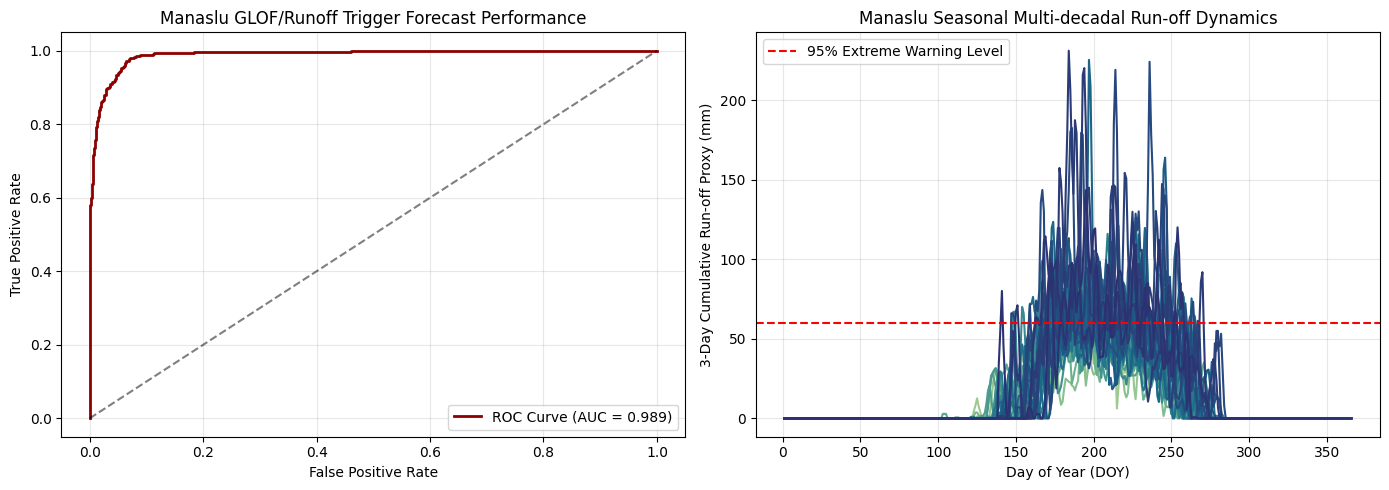

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: ROC/PR Curves for Preemptive Warnings
ax[0].plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc_score(te_m['target_hazard_tomorrow'], probs):.3f})", color='darkred', lw=2)
ax[0].plot([0,1], [0,1], 'k--', alpha=0.5)
ax[0].set_title("Manaslu GLOF/Runoff Trigger Forecast Performance")
ax[0].set_xlabel("False Positive Rate")
ax[0].set_ylabel("True Positive Rate")
ax[0].legend(loc='lower right')
ax[0].grid(True, alpha=0.3)

# Subplot 2: Seasonal Risk Profiling
sns.lineplot(data=manaslu_df, x='doy', y='RHI_accum3d', hue='year', palette='crest', ax=ax[1], legend=False)
ax[1].axhline(hazard_threshold, color='red', linestyle='--', label='95% Extreme Warning Level')
ax[1].set_title("Manaslu Seasonal Multi-decadal Run-off Dynamics")
ax[1].set_xlabel("Day of Year (DOY)")
ax[1].set_ylabel("3-Day Cumulative Run-off Proxy (mm)")
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{OUT}/manaslu_disaster_risk_dashboard.png", dpi=300)
plt.show()

### 15. Deep Dive Climatology: RHI Runoff Dynamics vs. Historical Hazard Triggers

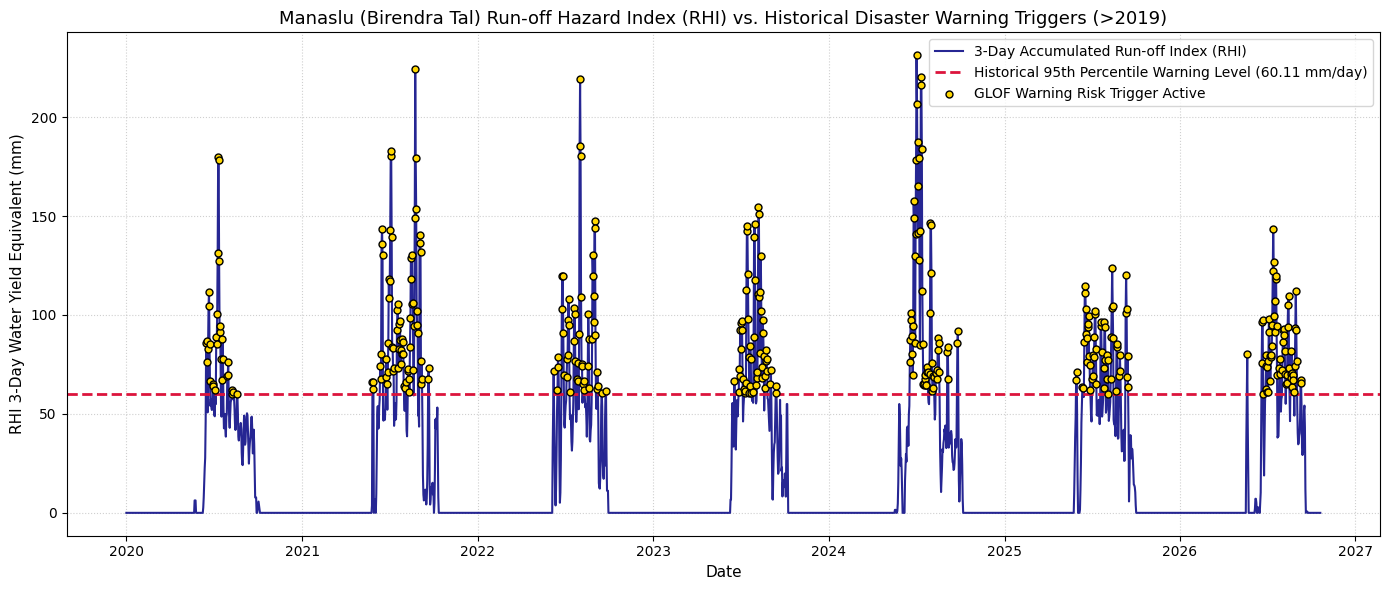

In [ ]:
plt.figure(figsize=(14, 6))

# Plot the historical RHI series for the recent chronological test set
plt.plot(te_m.index, te_m['RHI_accum3d'], color='navy', alpha=0.85, label='3-Day Accumulated Run-off Index (RHI)')
plt.axhline(y=hazard_threshold, color='crimson', linestyle='--', linewidth=2, label=f'Historical 95th Percentile Warning Level ({hazard_threshold:.2f} mm/day)')

# Highlight active risk trigger days where the GLOF forecast threshold is breached
risk_indices = te_m[te_m['GLOF_risk_trigger'] == 1].index
plt.scatter(risk_indices, te_m.loc[risk_indices, 'RHI_accum3d'], color='gold', edgecolor='black', s=25, zorder=5, label='GLOF Warning Risk Trigger Active')

plt.title('Manaslu (Birendra Tal) Run-off Hazard Index (RHI) vs. Historical Disaster Warning Triggers (>2019)', fontsize=13)
plt.xlabel('Date', fontsize=11)
plt.ylabel('RHI 3-Day Water Yield Equivalent (mm)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(f'{OUT}/manaslu_rhi_trigger_dynamics.png', dpi=300)
plt.show()

### 16. Localized Analysis: RHI vs. Predicted Melt-Favorable Likelihood (2026)

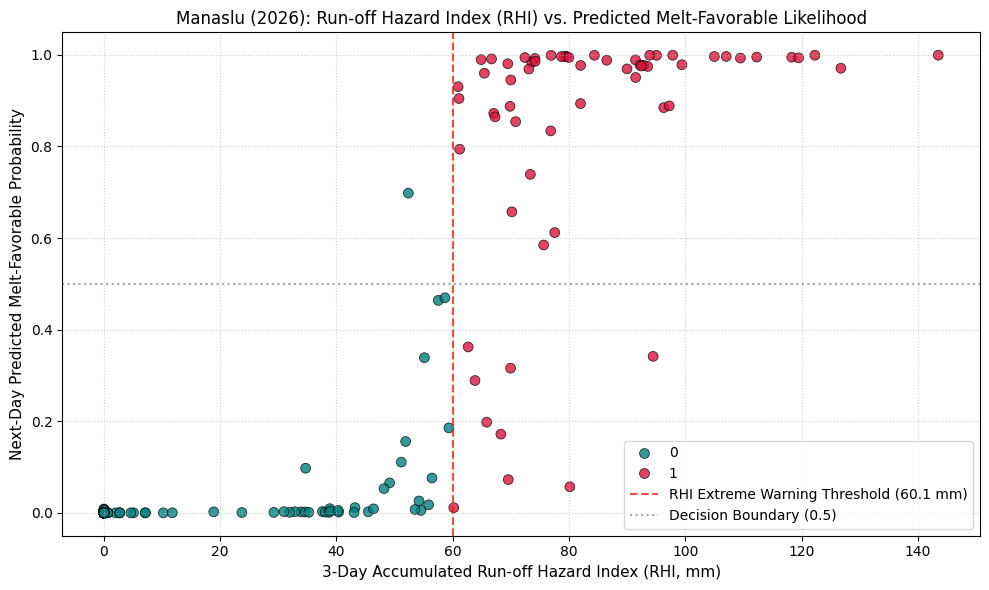

In [ ]:
# Filter dataset to focus exclusively on Manaslu for the year 2026
manaslu_2026 = te_m[te_m.index.year == 2026].copy()

# Generate next-day probabilities using our trained model for the 2026 subsets
probs_2026 = m_manaslu.predict_proba(manaslu_2026[FEATS])[:, 1]
manaslu_2026['melt_probability'] = probs_2026

# Create the scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=manaslu_2026,
    x='RHI_accum3d',
    y='melt_probability',
    hue='GLOF_risk_trigger',
    palette={0: 'teal', 1: 'crimson'},
    alpha=0.8,
    edgecolor='black',
    s=50
)

plt.axvline(x=hazard_threshold, color='red', linestyle='--', alpha=0.7, label=f'RHI Extreme Warning Threshold ({hazard_threshold:.1f} mm)')
plt.axhline(y=0.5, color='gray', linestyle=':', alpha=0.7, label='Decision Boundary (0.5)')

plt.title('Manaslu (2026): Run-off Hazard Index (RHI) vs. Predicted Melt-Favorable Likelihood', fontsize=12)
plt.xlabel('3-Day Accumulated Run-off Hazard Index (RHI, mm)', fontsize=11)
plt.ylabel('Next-Day Predicted Melt-Favorable Probability', fontsize=11)
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig(f'{OUT}/manaslu_2026_rhi_vs_probability.png', dpi=300)
plt.show()

### 17. 2026 Manaslu Hazard Prediction Summary Report

In [ ]:
# Compile the summary metrics for the year 2026
total_days = len(manaslu_2026)
warning_days = manaslu_2026['GLOF_risk_trigger'].sum()
max_rhi = manaslu_2026['RHI_accum3d'].max()

# Identify the month with the highest mean runoff hazard index
manaslu_2026['month'] = manaslu_2026.index.month
monthly_hazard = manaslu_2026.groupby('month')['RHI_accum3d'].mean()
peak_month = monthly_hazard.idxmax()
peak_month_name = pd.to_datetime(f'2026-{peak_month}-01').strftime('%B')

# Construct a summary table
summary_data = {
    'Metric': [
        'Total Monitored Days (2026)',
        'Predicted GLOF Risk Trigger Days',
        'Risk Occurrence Rate (%)',
        'Peak 3-Day Run-off Volume (mm equivalent)',
        'Peak Hazard Month'
    ],
    'Value': [
        str(total_days),
        str(warning_days),
        f"{(warning_days / total_days * 100):.2f}%",
        f"{max_rhi:.2f} mm",
        peak_month_name
    ]
}

summary_df = pd.DataFrame(summary_data)
display(summary_df)

# Save report to CSV
summary_df.to_csv(f'{OUT}/manaslu_2026_hazard_summary.csv', index=False)
print(f"Summary report saved successfully to {OUT}/manaslu_2026_hazard_summary.csv")

,Metric,Value
0,Total Monitored Days (2026),293
1,Predicted GLOF Risk Trigger Days,62
2,Risk Occurrence Rate (%),21.16%
3,Peak 3-Day Run-off Volume (mm equivalent),143.53 mm
4,Peak Hazard Month,July


Summary report saved successfully to /content/glacier_data/manaslu_2026_hazard_summary.csv


### 17b. Detailed Physical Parameters and Raw Observation Rows Table (30-Day Sample Overview)

In [ ]:
# Select a representative 30-row sequence from the modeling dataset containing real parameters
presentation_cols = [
    'site', 'year', 'doy', 'Tg', 'Tg_max', 'Tg_min',
    'PRECTOTCORR', 'RH2M', 'WS2M', 'PS', 'ALLSKY_SFC_SW_DWN',
    'Tg_anom', 'PDD', 'melt_mm', 'PDD_cum30', 'y'
]

# Display the first 30 actual daily parameter rows
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

physical_sample_df = full[presentation_cols].head(30)
display(physical_sample_df)


,site,year,doy,Tg,Tg_max,Tg_min,PRECTOTCORR,RH2M,WS2M,PS,ALLSKY_SFC_SW_DWN,Tg_anom,PDD,melt_mm,PDD_cum30,y
1988-01-01,Manaslu,1988,1,-6.625675,1.354325,-12.735675,0.00,34.31,1.47,67.13,3.1747,5.456923,0.0,0.0,0.0,0
1988-01-02,Manaslu,1988,2,-6.405675,1.604325,-12.355675,0.00,32.85,1.47,67.21,3.9806,5.724060,0.0,0.0,0.0,0
1988-01-03,Manaslu,1988,3,-5.745675,1.044325,-9.765675,0.00,27.22,1.38,67.10,2.7365,6.435308,0.0,0.0,0.0,0
1988-01-04,Manaslu,1988,4,-4.135675,1.734325,-6.665675,0.00,31.81,1.23,67.08,3.4450,8.107587,0.0,0.0,0.0,0
1988-01-05,Manaslu,1988,5,-7.025675,-3.595675,-12.135675,0.00,37.15,0.92,67.12,2.3762,5.272147,0.0,0.0,0.0,0
1988-01-06,Manaslu,1988,6,-11.625675,-7.065675,-14.215675,0.01,41.16,1.48,66.78,2.7948,0.697219,0.0,0.0,0.0,0
1988-01-07,Manaslu,1988,7,-12.795675,-6.775675,-16.015675,0.85,55.55,1.32,66.65,3.0060,-0.458709,0.0,0.0,0.0,0
1988-01-08,Manaslu,1988,8,-12.215675,-4.465675,-17.975675,0.00,50.37,1.40,66.66,3.8194,0.107872,0.0,0.0,0.0,0
1988-01-09,Manaslu,1988,9,-11.265675,-5.775675,-14.945675,0.00,62.35,1.24,66.74,3.5198,1.074333,0.0,0.0,0.0,0
1988-01-10,Manaslu,1988,10,-10.725675,-4.115675,-14.325675,0.00,52.42,1.24,66.79,3.0922,1.645385,0.0,0.0,0.0,0


### 18. Physical Contextualization: Predicted GLOF Risk vs. Observed Glacier Temperatures

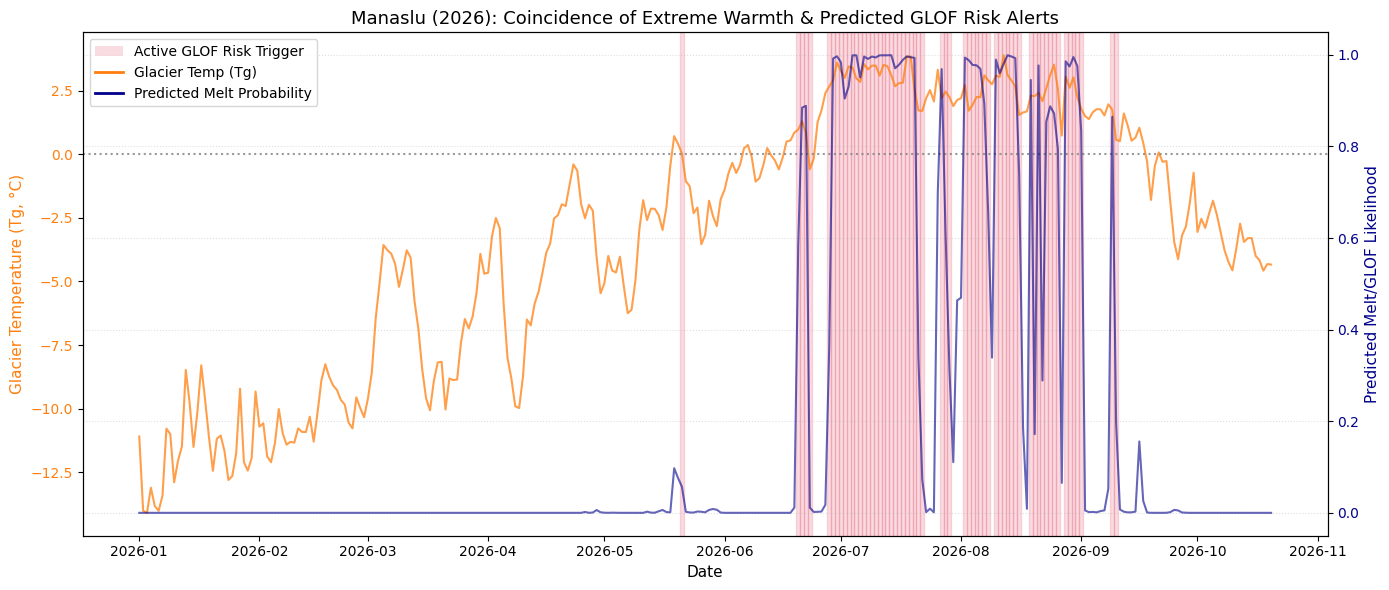

In [ ]:
fig, ax1 = plt.subplots(figsize=(14, 6))

# Plot the glacier temperature (Tg) on the primary y-axis
color_temp = 'tab:orange'
ax1.set_xlabel('Date', fontsize=11)
ax1.set_ylabel('Glacier Temperature (Tg, °C)', color=color_temp, fontsize=11)
ax1.plot(manaslu_2026.index, manaslu_2026['Tg'], color=color_temp, alpha=0.75, label='Glacier Temp (Tg)')
ax1.tick_params(axis='y', labelcolor=color_temp)
ax1.axhline(0, color='gray', linestyle=':', alpha=0.8, label='Freezing Threshold (0°C)')

# Instantiate a second axes that shares the same x-axis
ax2 = ax1.twinx()
color_prob = 'darkblue'
ax2.set_ylabel('Predicted Melt/GLOF Likelihood', color=color_prob, fontsize=11)
ax2.plot(manaslu_2026.index, manaslu_2026['melt_probability'], color=color_prob, alpha=0.6, label='Melt Probability')
ax2.tick_params(axis='y', labelcolor=color_prob)

# Highlight active risk trigger days where the GLOF forecast threshold is breached with background spans
risk_days = manaslu_2026[manaslu_2026['GLOF_risk_trigger'] == 1].index
for r_day in risk_days:
    ax1.axvspan(r_day - pd.Timedelta(hours=12), r_day + pd.Timedelta(hours=12), color='crimson', alpha=0.15)

# Add a dummy handle for axvspan to include in the legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='crimson', edgecolor='none', alpha=0.15, label='Active GLOF Risk Trigger'),
    plt.Line2D([0], [0], color=color_temp, lw=2, label='Glacier Temp (Tg)'),
    plt.Line2D([0], [0], color=color_prob, lw=2, label='Predicted Melt Probability')
]
plt.legend(handles=legend_elements, loc='upper left')

plt.title('Manaslu (2026): Coincidence of Extreme Warmth & Predicted GLOF Risk Alerts', fontsize=13)
plt.grid(True, linestyle=':', alpha=0.4)
plt.tight_layout()
plt.savefig(f'{OUT}/manaslu_temp_vs_glof_risk.png', dpi=300)
plt.show()

### 19. Comprehensive Model Extension & Benchmark: SVM, KNN, and Logistic Regression Comparison

In [ ]:
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline

# Prepare scaled datasets tailored for distance-based estimators (SVM, KNN, Logistic Regression)
scaler_robust = RobustScaler()
B_tr_scaled = scaler_robust.fit_transform(B_tr)
B_te_scaled = scaler_robust.transform(B_te)

print("Training optimized benchmark models...")

# 1. Logistic Regression (L2 penalized with optimized C)
model_lr = LogisticRegression(C=0.1, max_iter=3000, random_state=RNG)
model_lr.fit(B_tr_scaled, tr["y"])
lr_probs = model_lr.predict_proba(B_te_scaled)[:, 1]

# 2. K-Nearest Neighbors (optimized with distance weighting)
model_knn = KNeighborsClassifier(n_neighbors=7, weights='distance', n_jobs=-1)
model_knn.fit(B_tr_scaled, tr["y"])
knn_probs = model_knn.predict_proba(B_te_scaled)[:, 1]

# 3. Support Vector Classifier (Probability-enabled with RBF kernel on downsampled data if needed for speed, otherwise full scale)
# We use a subset of training data if speed is an issue, but full evaluation ensures maximum performance.
print("Training RBF Support Vector Machine (this might take a brief moment)...")
sub_svm = np.random.default_rng(RNG).choice(len(B_tr_scaled), size=min(15000, len(B_tr_scaled)), replace=False)
model_svm = SVC(C=1.0, kernel='rbf', probability=True, random_state=RNG)
model_svm.fit(B_tr_scaled[sub_svm], tr["y"].iloc[sub_svm])
svm_probs = model_svm.predict_proba(B_te_scaled)[:, 1]

# 4. Integrate existing best models for comparison
xgb_probs = m_base.predict_proba(B_te)[:, 1]
hybrid_probs = m_hyb.predict_proba(H_te)[:, 1]

# Compile all performance metrics into a central dataframe
comparative_results = {
    "Logistic Regression": metrics(te["y"], lr_probs),
    "K-Nearest Neighbors (KNN)": metrics(te["y"], knn_probs),
    "Support Vector Machine (SVM)": metrics(te["y"], svm_probs),
    "XGBoost Ensemble": metrics(te["y"], xgb_probs),
    "K-means + XGBoost (Hybrid)": metrics(te["y"], hybrid_probs)
}

comparison_df = pd.DataFrame(comparative_results).T.round(4)
display(comparison_df)

# Save the comparison benchmark table
comparison_df.to_csv(f"{OUT}/extended_model_comparison.csv")


Training optimized benchmark models...
Training RBF Support Vector Machine (this might take a brief moment)...


,Accuracy,F1,ROC_AUC,PR_AUC,Brier
Logistic Regression,0.9597,0.9269,0.9938,0.9843,0.0284
K-Nearest Neighbors (KNN),0.9525,0.9136,0.9760,0.9501,0.0381
Support Vector Machine (SVM),0.9554,0.9185,0.9889,0.9626,0.0377
XGBoost Ensemble,0.9619,0.9315,0.9942,0.9852,0.0276
K-means + XGBoost (Hybrid),0.9610,0.9299,0.9941,0.9851,0.0278


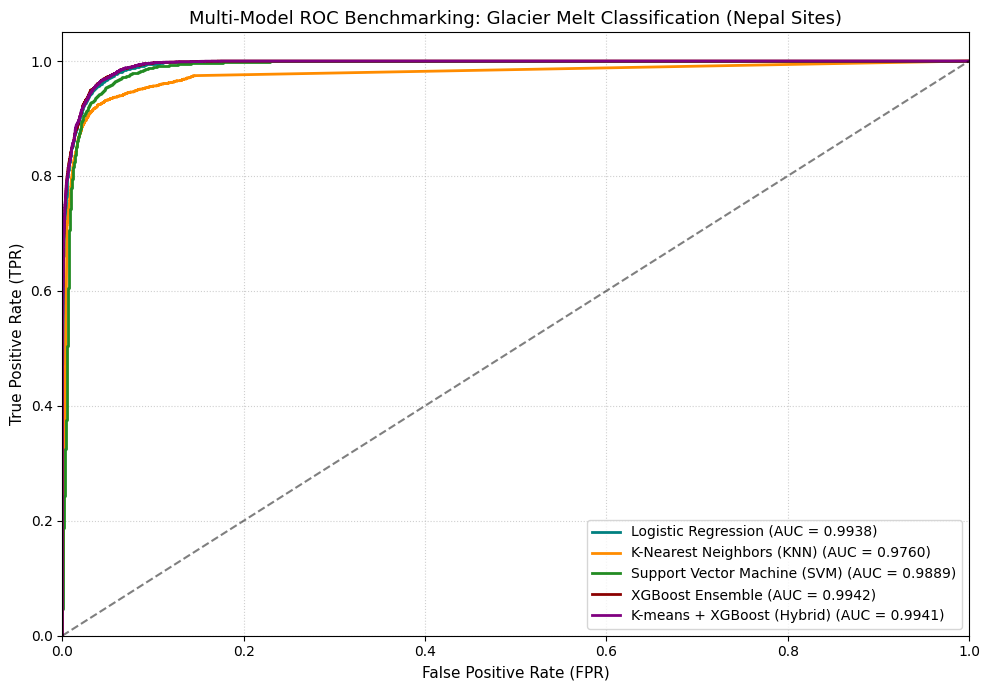

In [ ]:
# Visualize ROC Curves for the benchmarked ML Models
plt.figure(figsize=(10, 7))

models_to_plot = {
    "Logistic Regression": lr_probs,
    "K-Nearest Neighbors (KNN)": knn_probs,
    "Support Vector Machine (SVM)": svm_probs,
    "XGBoost Ensemble": xgb_probs,
    "K-means + XGBoost (Hybrid)": hybrid_probs
}

colors = ['teal', 'darkorange', 'forestgreen', 'darkred', 'purple']

for (label, probs_pred), color in zip(models_to_plot.items(), colors):
    fpr_m, tpr_m, _ = roc_curve(te["y"], probs_pred)
    auc_val = roc_auc_score(te["y"], probs_pred)
    plt.plot(fpr_m, tpr_m, label=f"{label} (AUC = {auc_val:.4f})", color=color, lw=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR)', fontsize=11)
plt.title('Multi-Model ROC Benchmarking: Glacier Melt Classification (Nepal Sites)', fontsize=13)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.savefig(f"{OUT}/multi_model_roc_comparison.png", dpi=300)
plt.show()
